Import Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
)

from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.20.0
GPU available: []


Load & Explore CIFAR-10

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 186s 1us/step

── Dataset shapes ──
X_train : (50000, 32, 32, 3)   y_train : (50000, 1)
X_test  : (10000, 32, 32, 3)    y_test  : (10000, 1)
Pixel range before normalisation: 0 – 255


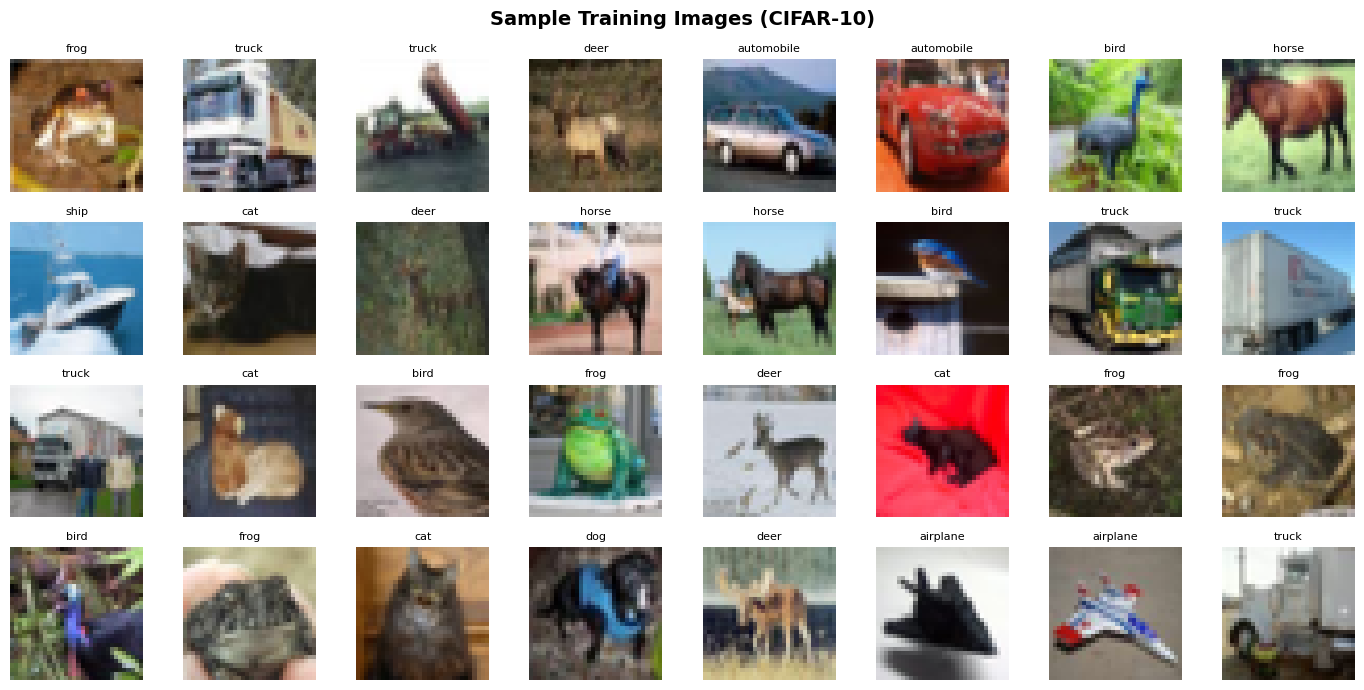

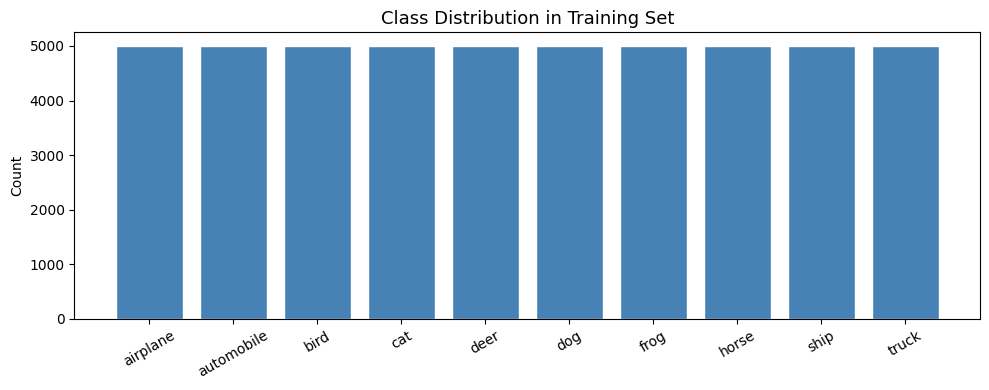

In [2]:
(X_train, y_train), (X_test, y_test) = keras.datasets.cifar10.load_data()

CLASS_NAMES = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]
NUM_CLASSES = len(CLASS_NAMES)

print("\n── Dataset shapes ──")
print(f"X_train : {X_train.shape}   y_train : {y_train.shape}")
print(f"X_test  : {X_test.shape}    y_test  : {y_test.shape}")
print(f"Pixel range before normalisation: {X_train.min()} – {X_train.max()}")

# Visualise a sample grid
fig, axes = plt.subplots(4, 8, figsize=(14, 7))
axes = axes.ravel()
for i in range(32):
    axes[i].imshow(X_train[i])
    axes[i].set_title(CLASS_NAMES[y_train[i][0]], fontsize=8)
    axes[i].axis('off')
plt.suptitle("Sample Training Images (CIFAR-10)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Class distribution
unique, counts = np.unique(y_train, return_counts=True)
plt.figure(figsize=(10, 4))
plt.bar([CLASS_NAMES[i] for i in unique], counts, color='steelblue', edgecolor='white')
plt.title("Class Distribution in Training Set", fontsize=13)
plt.ylabel("Count")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Normalize & one-hot encode

In [3]:
X_train = X_train.astype('float32') / 255.0
X_test  = X_test.astype('float32')  / 255.0

# 3b. One-hot encode labels
y_train_ohe = to_categorical(y_train, NUM_CLASSES)
y_test_ohe  = to_categorical(y_test,  NUM_CLASSES)

print("\n── After preprocessing ──")
print(f"Pixel range    : {X_train.min()} – {X_train.max()}")
print(f"y_train shape  : {y_train_ohe.shape}   (one-hot)")

# 3c. Validation split (10 % of training data)
VAL_SPLIT = 0.1
val_size  = int(len(X_train) * VAL_SPLIT)

X_val, y_val       = X_train[:val_size],  y_train_ohe[:val_size]
X_train2, y_train2 = X_train[val_size:],  y_train_ohe[val_size:]

print(f"\nTrain   : {X_train2.shape[0]} samples")
print(f"Val     : {X_val.shape[0]}    samples")
print(f"Test    : {X_test.shape[0]}  samples")


── After preprocessing ──
Pixel range    : 0.0 – 1.0
y_train shape  : (50000, 10)   (one-hot)

Train   : 45000 samples
Val     : 5000    samples
Test    : 10000  samples


Data augmentation

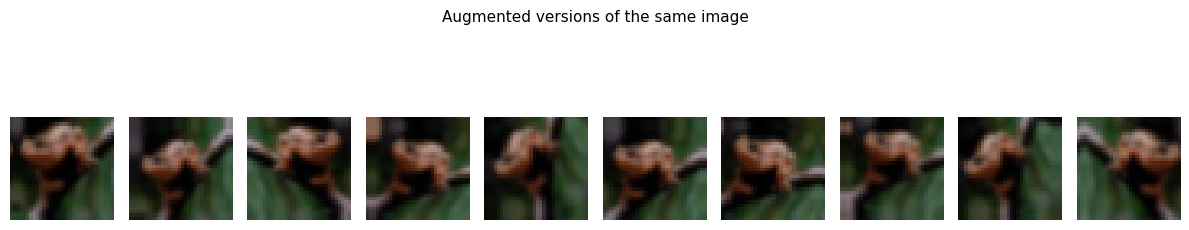

In [4]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.10),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.10, 0.10),
], name="data_augmentation")

# Preview augmented images
sample_img = X_train2[0:1]
plt.figure(figsize=(12, 3))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    aug = data_augmentation(sample_img, training=True)
    plt.imshow(aug[0])
    plt.axis('off')
plt.suptitle("Augmented versions of the same image", fontsize=11)
plt.tight_layout()
plt.show()

Build CNN architecture

Model: "CIFAR10_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,049,08

 Total params: 1,345,066 (5.13 MB)

 Trainable params: 1,343,146 (5.12 MB)

 Non-trainable params: 1,920 (7.50 KB)

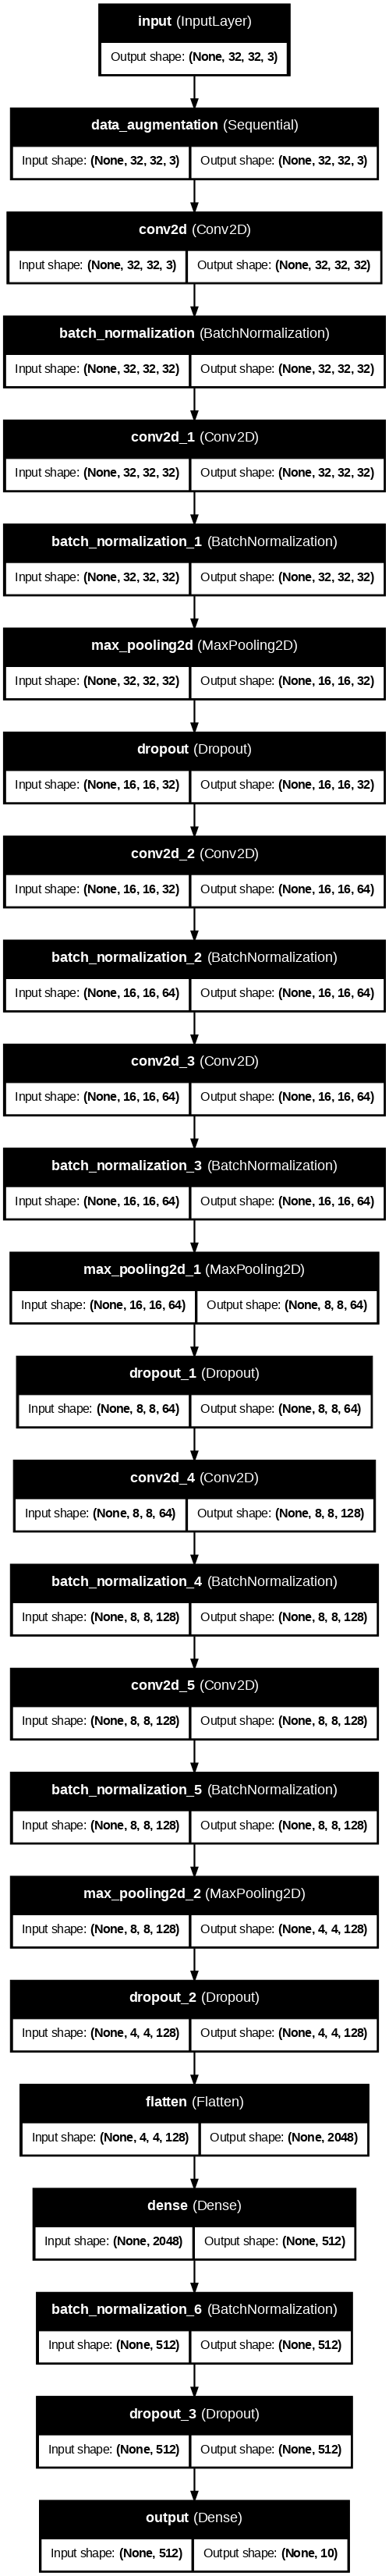

In [5]:
def build_cnn(input_shape=(32, 32, 3), num_classes=10):
    inputs = keras.Input(shape=input_shape, name="input")

    # ── Augmentation (active only during training) ──
    x = data_augmentation(inputs)

    # ── Block 1 ──
    x = layers.Conv2D(32, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(32, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.25)(x)

    # ── Block 2 ──
    x = layers.Conv2D(64, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(64, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.30)(x)

    # ── Block 3 ──
    x = layers.Conv2D(128, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(128, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.40)(x)

    # ── Classifier Head ──
    x = layers.Flatten()(x)
    x = layers.Dense(512, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.50)(x)
    outputs = layers.Dense(num_classes, activation='softmax', name="output")(x)

    model = keras.Model(inputs, outputs, name="CIFAR10_CNN")
    return model


model = build_cnn()
model.summary()

# Visualise layer shapes as a table
keras.utils.plot_model(
    model, show_shapes=True, show_layer_names=True,
    to_file='model_architecture.png', dpi=80
)

Compile (Adam + CrossEntropy)

In [6]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("\nModel compiled ✔")
print(f"Total parameters: {model.count_params():,}")


Model compiled ✔
Total parameters: 1,345,066


Callbacks (EarlyStopping, ReduceLR, Checkpoint)

In [7]:
callbacks = [
    # Stop early if val_loss stops improving for 10 epochs
    EarlyStopping(monitor='val_loss', patience=10,
                  restore_best_weights=True, verbose=1),

    # Halve LR if val_loss stagnates for 5 epochs
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=5, min_lr=1e-6, verbose=1),

    # Save the best checkpoint
    ModelCheckpoint('best_cnn_model.keras',
                    monitor='val_accuracy', save_best_only=True, verbose=1),
]

Train model

In [8]:
BATCH_SIZE = 64
EPOCHS     = 50          # EarlyStopping will exit earlier if needed

print("\n🚀 Starting training …\n")
history = model.fit(
    X_train2, y_train2,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=(X_val, y_val),
    callbacks=callbacks,
    verbose=1
)
print("\n✅ Training complete!")


🚀 Starting training …

Epoch 1/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 0s 551ms/step - accuracy: 0.2891 - loss: 2.3442
Epoch 1: val_accuracy improved from None to 0.45200, saving model to best_cnn_model.keras

Epoch 1: finished saving model to best_cnn_model.keras
704/704 ━━━━━━━━━━━━━━━━━━━━ 405s 565ms/step - accuracy: 0.3490 - loss: 1.9668 - val_accuracy: 0.4520 - val_loss: 1.6681 - learning_rate: 0.0010
Epoch 2/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 0s 540ms/step - accuracy: 0.4485 - loss: 1.5368
Epoch 2: val_accuracy did not improve from 0.45200
704/704 ━━━━━━━━━━━━━━━━━━━━ 389s 553ms/step - accuracy: 0.4691 - loss: 1.4773 - val_accuracy: 0.4484 - val_loss: 1.8654 - learning_rate: 0.0010
Epoch 3/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 0s 538ms/step - accuracy: 0.5180 - loss: 1.3399
Epoch 3: val_accuracy improved from 0.45200 to 0.49300, saving model to best_cnn_model.keras

Epoch 3: finished saving model to best_cnn_model.keras
704/704 ━━━━━━━━━━━━━━━━━━━━ 389s 552ms/step - accuracy: 0.5301 - loss: 1.30

Plot accuracy & loss curves

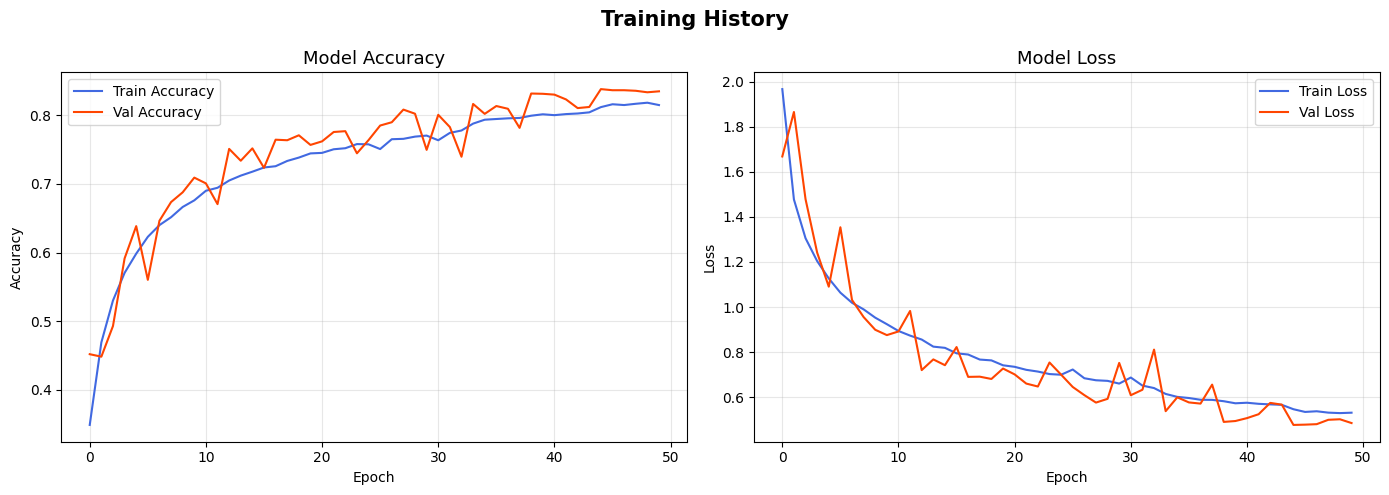

In [9]:
def plot_history(history):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Accuracy
    ax1.plot(history.history['accuracy'],     label='Train Accuracy',  color='royalblue')
    ax1.plot(history.history['val_accuracy'], label='Val Accuracy',    color='orangered')
    ax1.set_title('Model Accuracy',  fontsize=13)
    ax1.set_xlabel('Epoch'); ax1.set_ylabel('Accuracy')
    ax1.legend(); ax1.grid(alpha=0.3)

    # Loss
    ax2.plot(history.history['loss'],     label='Train Loss',  color='royalblue')
    ax2.plot(history.history['val_loss'], label='Val Loss',    color='orangered')
    ax2.set_title('Model Loss', fontsize=13)
    ax2.set_xlabel('Epoch'); ax2.set_ylabel('Loss')
    ax2.legend(); ax2.grid(alpha=0.3)

    plt.suptitle('Training History', fontsize=15, fontweight='bold')
    plt.tight_layout()
    plt.show()

plot_history(history)

Evaluate on test set

In [10]:
print("\n── Test Set Evaluation ──")
test_loss, test_acc = model.evaluate(X_test, y_test_ohe, verbose=0)
print(f"Test Accuracy : {test_acc * 100:.2f} %")
print(f"Test Loss     : {test_loss:.4f}")


── Test Set Evaluation ──
Test Accuracy : 83.14 %
Test Loss     : 0.5114


Confusion matrix & classification report

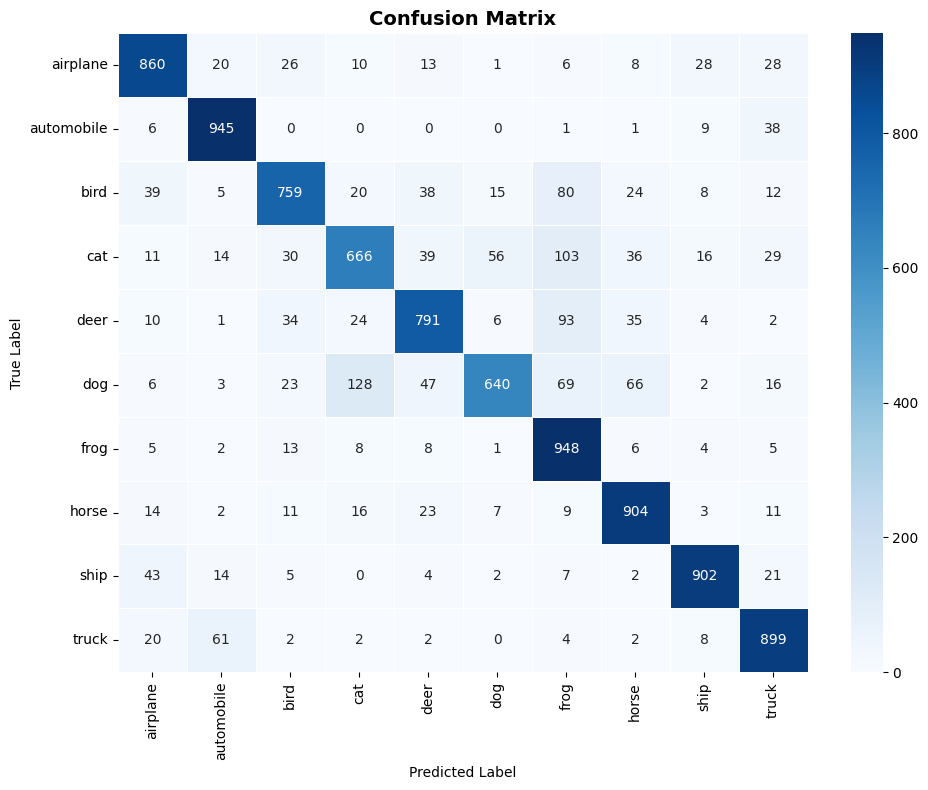


── Classification Report ──

              precision    recall  f1-score   support

    airplane       0.85      0.86      0.85      1000
  automobile       0.89      0.94      0.91      1000
        bird       0.84      0.76      0.80      1000
         cat       0.76      0.67      0.71      1000
        deer       0.82      0.79      0.81      1000
         dog       0.88      0.64      0.74      1000
        frog       0.72      0.95      0.82      1000
       horse       0.83      0.90      0.87      1000
        ship       0.92      0.90      0.91      1000
       truck       0.85      0.90      0.87      1000

    accuracy                           0.83     10000
   macro avg       0.84      0.83      0.83     10000
weighted avg       0.84      0.83      0.83     10000



In [11]:
y_pred_probs = model.predict(X_test, verbose=0)
y_pred       = np.argmax(y_pred_probs, axis=1)
y_true       = y_test.flatten()

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            linewidths=0.5)
plt.title('Confusion Matrix', fontsize=14, fontweight='bold')
plt.ylabel('True Label'); plt.xlabel('Predicted Label')
plt.tight_layout()
plt.show()

# Per-class report
print("\n── Classification Report ──\n")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

Visualise predictions

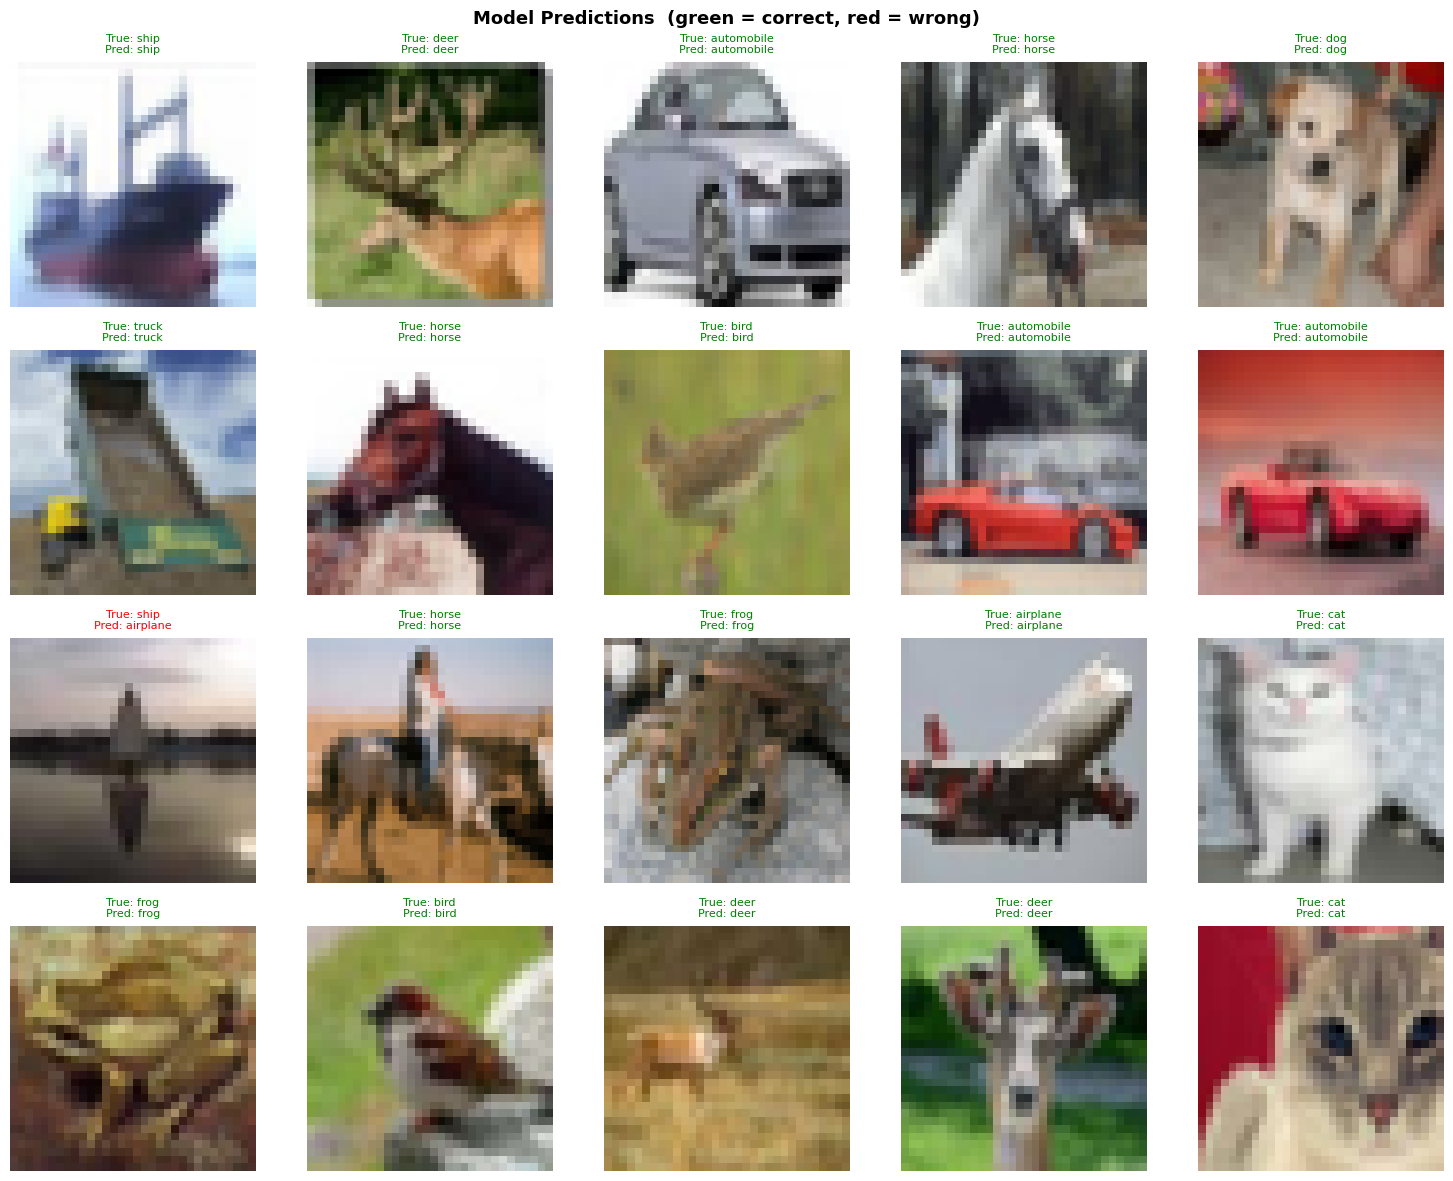

In [12]:
def show_predictions(n=20):
    indices = np.random.choice(len(X_test), n, replace=False)
    images  = X_test[indices]
    labels  = y_true[indices]
    preds   = y_pred[indices]

    cols = 5
    rows = n // cols
    fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 3))
    axes = axes.ravel()

    for i, (img, true, pred) in enumerate(zip(images, labels, preds)):
        axes[i].imshow(img)
        color = 'green' if true == pred else 'red'
        axes[i].set_title(
            f"True: {CLASS_NAMES[true]}\nPred: {CLASS_NAMES[pred]}",
            fontsize=8, color=color
        )
        axes[i].axis('off')

    plt.suptitle("Model Predictions  (green = correct, red = wrong)",
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

show_predictions(20)

Save & reload model

In [13]:
model.save('cnn_cifar10_final.keras')
print("Model saved → cnn_cifar10_final.keras")

# Reload and verify
loaded_model = keras.models.load_model('cnn_cifar10_final.keras')
_, reloaded_acc = loaded_model.evaluate(X_test, y_test_ohe, verbose=0)
print(f"Reloaded model accuracy: {reloaded_acc * 100:.2f} %  ✔")

Model saved → cnn_cifar10_final.keras
Reloaded model accuracy: 83.14 %  ✔


Single-image prediction function


Predicted class : bird  (72.6 %)

All class probabilities:
  airplane       0.7%  
  automobile     0.1%  
  bird          72.6%  █████████████████████
  cat            1.5%  
  deer          10.6%  ███
  dog            0.3%  
  frog           4.2%  █
  horse          8.5%  ██
  ship           0.1%  
  truck          1.3%  


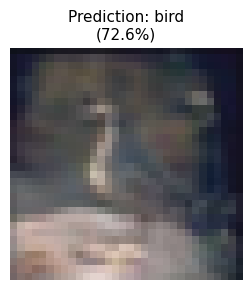

In [14]:
def predict_single(image_array):
    """
    Predict the class of a single image.
    image_array: numpy array of shape (32, 32, 3), pixel values 0-255 or 0-1.
    """
    img = image_array.astype('float32')
    if img.max() > 1.0:
        img /= 255.0                          # normalise if needed
    img = np.expand_dims(img, axis=0)         # add batch dimension → (1, 32, 32, 3)

    probs     = loaded_model.predict(img, verbose=0)[0]
    top_class = np.argmax(probs)

    print(f"\nPredicted class : {CLASS_NAMES[top_class]}  ({probs[top_class]*100:.1f} %)")
    print("\nAll class probabilities:")
    for name, p in zip(CLASS_NAMES, probs):
        bar = '█' * int(p * 30)
        print(f"  {name:12s} {p*100:5.1f}%  {bar}")

    plt.figure(figsize=(3, 3))
    plt.imshow(image_array if image_array.max() > 1 else image_array)
    plt.title(f"Prediction: {CLASS_NAMES[top_class]}\n({probs[top_class]*100:.1f}%)", fontsize=11)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

# Test on a random test image
sample_idx = np.random.randint(len(X_test))
predict_single(X_test[sample_idx])

Install Gradio

In [15]:
!pip install gradio -q

import numpy as np
import gradio as gr
import tensorflow as tf
from tensorflow import keras
from PIL import Image

Class Labels

In [16]:
CLASS_NAMES = [
    'airplane ✈️', 'automobile 🚗', 'bird 🐦', 'cat 🐱', 'deer 🦌',
    'dog 🐶',      'frog 🐸',       'horse 🐴', 'ship 🚢', 'truck 🚛'
]

Load the Saved Model

In [18]:
model = keras.models.load_model('cnn_cifar10_final.keras')
print("✅ Model loaded successfully!")

✅ Model loaded successfully!


Prediction Function

In [19]:
def predict(image):
    """
    Takes a PIL image from Gradio,
    resizes to 32×32, normalizes, and returns class probabilities.
    """
    img = Image.fromarray(image).resize((32, 32))
    arr = np.array(img).astype('float32') / 255.0
    arr = np.expand_dims(arr, axis=0)          # (1, 32, 32, 3)

    probs = model.predict(arr, verbose=0)[0]   # shape: (10,)

    # Return dict for Gradio label component
    return {CLASS_NAMES[i]: float(probs[i]) for i in range(10)}

Build Gradio Interface

In [20]:
demo = gr.Interface(
    fn=predict,

    inputs=gr.Image(
        label="Upload an image (airplane, car, bird, cat, deer, dog, frog, horse, ship, truck)",
        type="numpy"
    ),

    outputs=gr.Label(
        num_top_classes=3,
        label="Top Predictions"
    ),

    title="🖼️ CNN Image Classifier — CIFAR-10",
    description=(
        "Upload any image and the CNN will classify it into one of 10 categories.\n\n"
        "**Classes:** Airplane · Automobile · Bird · Cat · Deer · Dog · Frog · Horse · Ship · Truck"
    ),

    examples=[
        # Add local image paths here if you have sample images, e.g.:
        # ["sample_cat.jpg"],
        # ["sample_airplane.jpg"],
    ],

    theme=gr.themes.Soft(),
    allow_flagging="never"
)

/usr/local/lib/python3.12/dist-packages/gradio/interface.py:415: UserWarning: The `allow_flagging` parameter in `Interface` is deprecated. Use `flagging_mode` instead.
  warnings.warn(


Launch

In [21]:
demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://0e1aae40c8fef27600.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
